# Модуль 1 · Урок 8. Визуализация: Matplotlib, Seaborn, обзор Plotly
**AI-Driven ML Engineer · Data Science Academy**

| Время | Блок |
|---|---|
| 0–10 | Разминка «что выведет код» |
| 10–20 | Мостик: таблица урока 7 → график · вопросы по ДЗ 7 |
| 20–55 | Matplotlib: fig и ax, линия, столбики, гистограмма · Практика 1 |
| 55–90 | Seaborn: ящик с усами, barplot, тепловая карта · Практика 2 |
| 90–110 | Графики, которые врут · обзор Plotly · Практика 3: дашборд для менеджера |
| 110–120 | Итоги, ДЗ 8 |

**Правило занятия:** предскажи → запусти → объясни. **Правило графика:** заголовок – это вывод, и он проверен числом из таблицы.

## Разминка: что выведет код? (30 секунд на вопрос, без запуска)
```python
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# 1
print(pd.Series(["b", "a", "b", "c", "b", "a"]).value_counts().index.tolist())
# 2
print(plt.plot([10, 20, 15])[0].get_xdata())
# 3
sep, oct_ = 35.2, 34.4        # выручка, млн ₸
bottom = 34                   # ось Y начинается с 34
print(round((sep - bottom) / (oct_ - bottom), 1), round(sep / oct_, 2))
# 4
print(np.histogram([1, 2, 2, 3, 100], bins=2)[0])
# 5
fig, axes = plt.subplots(2, 3)
print(axes.shape, len(axes))
```

In [ ]:
# Проверьте ответы только ПОСЛЕ того, как написали их в чат

## Данные: orders.csv после очистки урока 6
Сегодня нужен только orders.csv. Проверка: 5 280 строк, 4 739 оплаченных.

In [1]:
# Загрузка orders.csv: в Colab нажмите «Выбрать файлы» и укажите orders.csv из LMS.
# Если файл уже лежит рядом с ноутбуком, загрузка пропускается.
import os
if not os.path.exists("orders.csv"):
    try:
        from google.colab import files
        files.upload()
    except ImportError:
        print("Положите orders.csv в одну папку с ноутбуком")
print("orders.csv на месте:", os.path.exists("orders.csv"))

orders.csv на месте: True


In [2]:
# Очистка урока 6 одной ячейкой: суммы, города, дубли, даты, TEST
import pandas as pd
import numpy as np

CITY = {"алматы": "Алматы", "almaty": "Алматы", "астана": "Астана", "astana": "Астана",
        "шымкент": "Шымкент", "shymkent": "Шымкент", "караганда": "Караганда",
        "актобе": "Актобе", "атырау": "Атырау"}

df = pd.read_csv("orders.csv")
df["amount"] = pd.to_numeric(df["amount"].str.replace(" ", ""))
df["city"] = df["city"].str.strip().str.lower().map(CITY)
df = df.drop_duplicates()
df["order_date"] = pd.to_datetime(df["order_date"])
df["month"] = df["order_date"].dt.month
df = df[df["customer_id"] != "TEST"].copy()    # copy: дальше добавим столбцы
df.shape

(5280, 9)

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

df["cancel"] = df["status"] == "отменён"     # True/False, урок 7
paid = df[df["status"] == "оплачен"]
len(paid)

4739

## Мостик: таблица урока 7 → график

In [4]:
p = paid.pivot_table(index="city", columns="month", values="amount", aggfunc="sum")
p

month,9,10
city,,
Актобе,2576960.0,2540420.0
Алматы,14501070.0,14643020.0
Астана,9034220.0,8850530.0
Атырау,923990.0,969860.0
Караганда,3648520.0,3371680.0
Шымкент,4558650.0,4044010.0


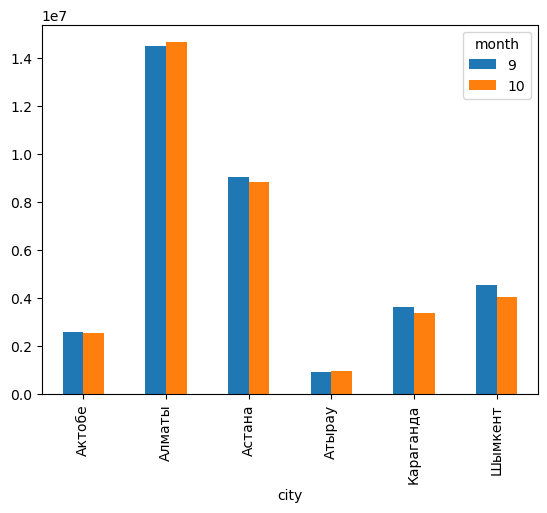

In [5]:
p.plot(kind="bar")      # Pandas рисует таблицу через Matplotlib одной строкой
plt.show()

Каждый столбец таблицы стал серией (9 и 10), ярлыки строк – подписями оси X. «1e7» над осью Y значит «× 10 млн»: делим на `1e6` и подписываем «млн ₸». Что видно? Почти ничего: столбики сентября и октября почти равны, Шымкент не выделяется. График без вопроса – просто картинка. Сегодня рисуем графики **под вывод**: сначала вопрос, потом форма графика, потом заголовок-вывод.

## 1. Matplotlib: fig и ax (01-Matplotlib Concepts)
`fig` – лист, `ax` – область с осями на этом листе. Всё рисуем методами `ax`.

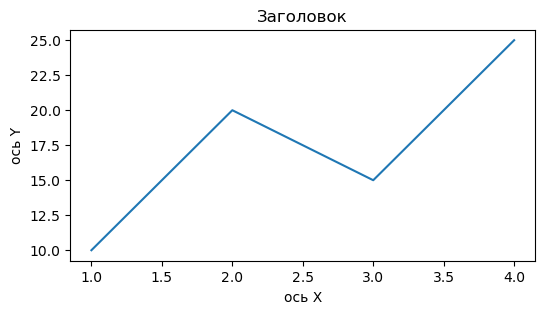

In [6]:
fig, ax = plt.subplots(figsize=(6, 3))     # ширина и высота в дюймах
ax.plot([1, 2, 3, 4], [10, 20, 15, 25])
ax.set_title("Заголовок")
ax.set_xlabel("ось X")
ax.set_ylabel("ось Y")
plt.show()

В 01-Matplotlib Concepts есть и короткая запись `plt.plot(...)`, `plt.title(...)`: она рисует на «текущей» области. AI пишет и так, и так. Мы пишем `fig, ax = plt.subplots()`: видно, где рисуем, и несколько графиков рядом делаются так же.

### Линия: как менялось во времени
Вопрос: когда сломалась доставка в Шымкенте? Средний срок по дням – `groupby` по дате (урок 7).

In [7]:
sh = df[df["city"] == "Шымкент"]
other = df[df["city"] != "Шымкент"]
sh_day = sh.groupby(sh["order_date"].dt.date)["delivery_days"].mean()
other_day = other.groupby(other["order_date"].dt.date)["delivery_days"].mean()


In [8]:
sh["order_date"]

5      2026-09-01 09:00:00
19     2026-09-01 11:00:00
25     2026-09-01 11:00:00
30     2026-09-01 12:00:00
31     2026-09-01 12:00:00
               ...        
5409   2026-10-31 12:00:00
5425   2026-10-31 15:00:00
5428   2026-10-31 15:00:00
5441   2026-10-31 17:00:00
5448   2026-10-31 18:00:00
Name: order_date, Length: 776, dtype: datetime64[ns]

In [9]:
sh["order_date"].dt.date.value_counts()

order_date
2026-09-02    24
2026-10-08    20
2026-10-10    20
2026-09-12    19
2026-10-20    19
              ..
2026-09-25     7
2026-10-31     7
2026-09-23     7
2026-09-07     6
2026-10-23     5
Name: count, Length: 61, dtype: int64

In [10]:
sh_day.iloc[52:53]

order_date
2026-10-23    7.2
Name: delivery_days, dtype: float64

In [11]:
other_day

order_date
2026-09-01    1.948052
2026-09-02    2.028169
2026-09-03    2.000000
2026-09-04    2.115385
2026-09-05    2.057971
                ...   
2026-10-27    2.039474
2026-10-28    2.000000
2026-10-29    2.172414
2026-10-30    2.038961
2026-10-31    2.126761
Name: delivery_days, Length: 61, dtype: float64

In [12]:
sh_day.iloc[27:33].round(2)

order_date
2026-09-28    2.19
2026-09-29    2.11
2026-09-30    2.33
2026-10-01    6.21
2026-10-02    7.30
2026-10-03    6.65
Name: delivery_days, dtype: float64

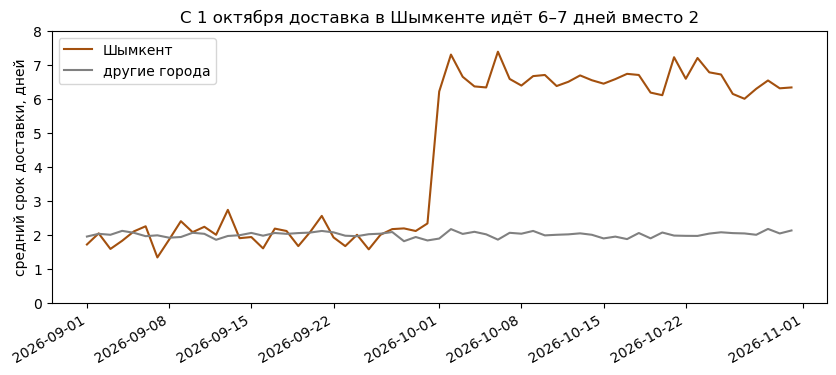

In [13]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(sh_day.index, sh_day.values, color="#A3500E", label="Шымкент")
ax.plot(other_day.index, other_day.values, color="gray", label="другие города")
ax.set_title("С 1 октября доставка в Шымкенте идёт 6–7 дней вместо 2")
ax.set_ylabel("средний срок доставки, дней")
ax.set_ylim(0, 8)
ax.legend()
fig.autofmt_xdate()       # подписи дат наклонно, чтобы не слипались
plt.show()

Заголовок – **вывод**, а не «Срок доставки по дням». Цвет – только у того, о чём вывод, остальное серым. Число в заголовке проверено таблицей выше.

### Столбики: сравнить группы

In [14]:
chg = ((p[10] / p[9] - 1) * 100).sort_values()
chg.round(1)

city
Шымкент     -11.3
Караганда    -7.6
Астана       -2.0
Актобе       -1.4
Алматы        1.0
Атырау        5.0
dtype: float64

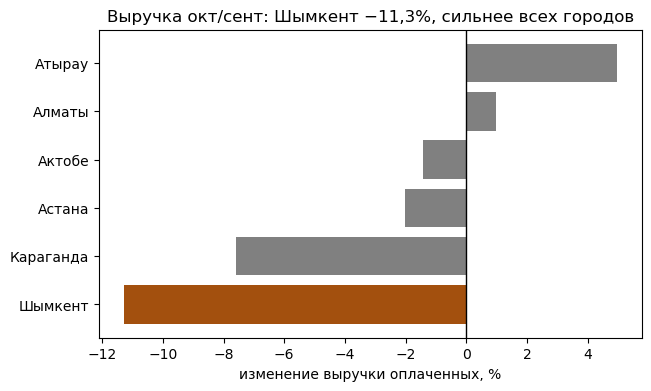

In [15]:
# ПРЕДСКАЖИТЕ: Шымкент окажется сверху или снизу?
colors = ["#A3500E" if c == "Шымкент" else "gray" for c in chg.index]
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(chg.index, chg.values, color=colors)
ax.axvline(0, color="black", linewidth=1)
ax.set_title("Выручка окт/сент: Шымкент −11,3%, сильнее всех городов")
ax.set_xlabel("изменение выручки оплаченных, %")
plt.show()

In [16]:
colors

['#A3500E', 'gray', 'gray', 'gray', 'gray', 'gray']

`barh` рисует первую строку **снизу**. Столбики сортируем по значению, а не по алфавиту: так глаз сразу находит лидера и аутсайдера.

### Гистограмма: как распределены суммы (вопрос 4 разминки)
`ax.hist` делит диапазон на `bins` равных корзин и считает, сколько значений попало в каждую. `plt.subplots(1, 2)` – два графика рядом, `axes[0]` и `axes[1]`.

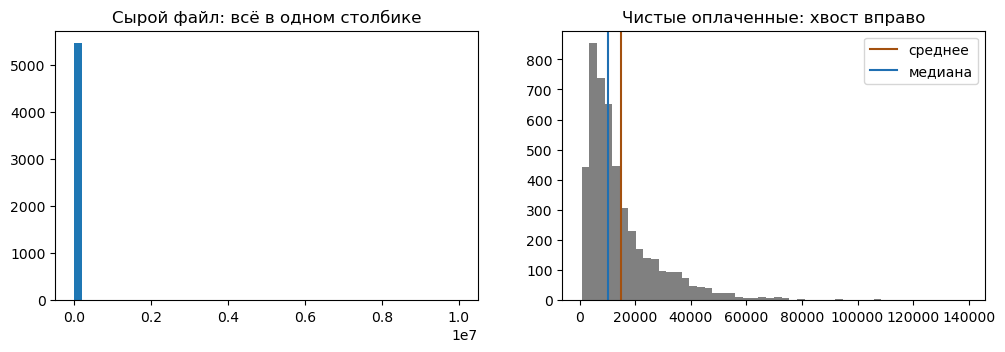

In [17]:
raw = pd.read_csv("orders.csv")
raw_amount = pd.to_numeric(raw["amount"].str.replace(" ", ""))

# ПРЕДСКАЖИТЕ: как выглядит левая гистограмма, где внутри три заказа TEST по 9 999 990 ₸?
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(raw_amount, bins=50)
axes[0].set_title("Сырой файл: всё в одном столбике")
axes[1].hist(paid["amount"], bins=50, color="gray")
axes[1].axvline(paid["amount"].mean(), color="#A3500E", label="среднее")
axes[1].axvline(paid["amount"].median(), color="#1F6FB2", label="медиана")
axes[1].set_title("Чистые оплаченные: хвост вправо")
axes[1].legend()
plt.show()

In [18]:
paid['amount'].describe()

count      4739.000000
mean      14699.921924
std       13292.965172
min         720.000000
25%        5890.000000
50%       10320.000000
75%       18710.000000
max      139040.000000
Name: amount, dtype: float64

In [43]:
paid["amount"].mean().round(), paid["amount"].median()

(14700.0, 10320.0)

Слева ось X дотянулась до 10 млн ради трёх заказов TEST, и 99,9% заказов слиплись в первый столбик. Если гистограмма – один столбик и пустота, ищем выброс. Справа хвост вправо: дорогие заказы тянут среднее (14 700 ₸) выше медианы (10 320 ₸).

Сохранить график для отчёта или EDA-проекта: `fig.savefig("hist.png", dpi=150, bbox_inches="tight")`.

## Практика 1, 12 минут
У каждого графика: заголовок-вывод, подписи осей с единицами, рядом печатаем число, которым проверили заголовок.
1. **[База]** Выручка оплаченных по категориям: `barh`, отсортировано. Сходится с ДЗ 4 (Электроника 34,4 млн ₸)?
2. **[База]** Число заказов по дням (`groupby` по `.dt.date`, `size()`) линией. Видно ли по числу заказов, что в октябре что-то сломалось?
3. **[Стандарт]** Доля отмен по городам столбиками, Шымкент цветом. Над столбиками – число заказов: `ax.bar_label(bars, labels=...)`, где `bars = ax.bar(...)`.
4. **[Челлендж]** Чек оплаченных: Шымкент и остальные города, две гистограммы рядом с `density=True`. Отличается ли чек? Почему без `density=True` сравнивать нельзя?

# 1[База] Выручка оплаченных по категориям: barh, отсортировано. Сходится с ДЗ 4 (Электроника 34,4 млн ₸)?

In [26]:
category_revenue = paid.groupby("category")["amount"].sum().sort_values()

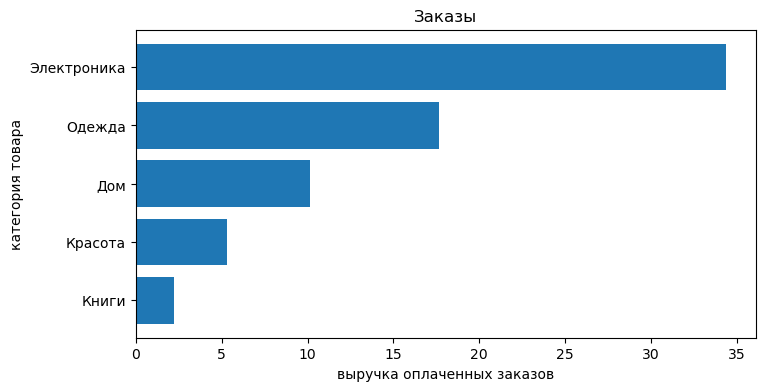

In [30]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(category_revenue.index, category_revenue.values / 1e6)
ax.set_title("Заказы")
ax.set_xlabel("выручка оплаченных заказов")
ax.set_ylabel("категория товара")
plt.show()

In [28]:
category_revenue

category
Книги           2206210.0
Красота         5289940.0
Дом            10123520.0
Одежда         17672830.0
Электроника    34370430.0
Name: amount, dtype: float64

электроника принесла 34.37млн это совпадает с дз4

# 2[База] Число заказов по дням (groupby по .dt.date, size()) линией. Видно ли по числу заказов, что в октябре что-то сломалось?

In [31]:
daily_orders = df.groupby(df["order_date"].dt.date).size()

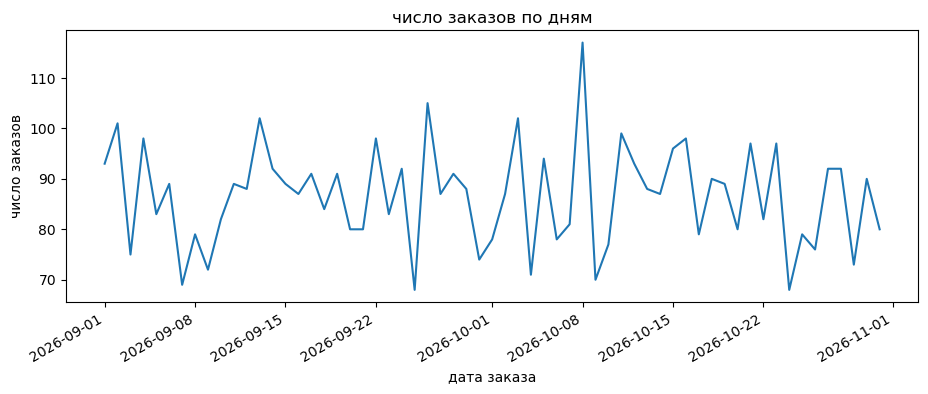

In [34]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(daily_orders.index, daily_orders.values)
ax.set_title("число заказов по дням")
ax.set_xlabel("дата заказа")
ax.set_ylabel("число заказов")
fig.autofmt_xdate()
plt.show()

In [33]:
daily_orders.loc[daily_orders.index.min():daily_orders.index.max()]

order_date
2026-09-01     93
2026-09-02    101
2026-09-03     75
2026-09-04     98
2026-09-05     83
             ... 
2026-10-27     92
2026-10-28     92
2026-10-29     73
2026-10-30     90
2026-10-31     80
Length: 61, dtype: int64

по графику не видно что что-то сломалось и стали падать заказы в октябре, значения колеблются примерно в том же диапазоне что и в сентябре

# 3[Стандарт] Доля отмен по городам столбиками, Шымкент цветом. Над столбиками – число заказов: ax.bar_label(bars, labels=...), где bars = ax.bar(...).

In [42]:
city_cancel = df.groupby("city")["cancel"].agg(["mean", "size"])
city_cancel = city_cancel.sort_values("mean")
colors = ["#A3500E" if city == "Шымкент" else "gray"
          for city in city_cancel.index]

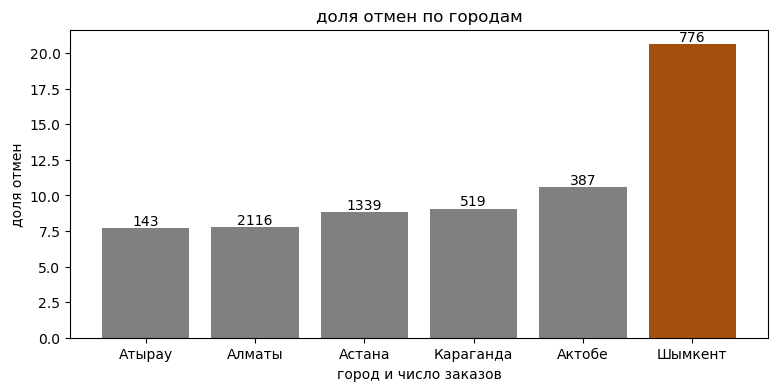

In [43]:
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(city_cancel.index, city_cancel["mean"] * 100, color=colors)
ax.bar_label(bars, labels=city_cancel["size"])
ax.set_title("доля отмен по городам")
ax.set_xlabel("город и число заказов")
ax.set_ylabel("доля отмен")
plt.show()

In [44]:
(city_cancel["mean"] * 100).round(1)

city
Атырау        7.7
Алматы        7.8
Астана        8.8
Караганда     9.1
Актобе       10.6
Шымкент      20.6
Name: mean, dtype: float64

# 4[Челлендж] Чек оплаченных: Шымкент и остальные города, две гистограммы рядом с density=True. Отличается ли чек? Почему без density=True сравнивать нельзя?

In [45]:
sh_amount = paid.loc[paid["city"] == "Шымкент", "amount"]
other_amount = paid.loc[paid["city"] != "Шымкент", "amount"]

Text(0.5, 1.0, 'чек оплаченных остальных городов')

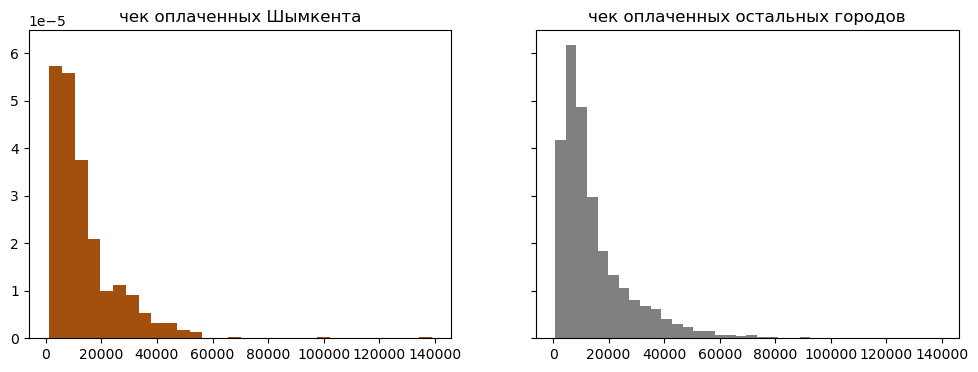

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
axes[0].hist(sh_amount, bins=30, density=True, color="#A3500E")
axes[0].set_title("чек оплаченных Шымкента")
axes[1].hist(other_amount, bins=30, density=True, color="gray")
axes[1].set_title("чек оплаченных остальных городов")

In [47]:
for ax in axes:
    ax.set_xlabel("сумма заказа")
    ax.set_ylabel("плотность")

In [48]:
plt.show()

In [49]:
paid.assign(
    group=np.where(paid["city"] == "Шымкент", "Шымкент", "Другие города")
).groupby("group")["amount"].agg(["mean", "median", "size"]).round(0)

,mean,median,size
group,,,
Другие города,14810.0,10350.0,4123
Шымкент,13965.0,9995.0,616


по гистограммам чеки в шымкенте и остальных городах выглядит похожим в обеих группах чаще встречаются небольшие суммы, крупные заказы редки
density=True приводит каждую гистограмму к общей площади 1 
без него высота столбиков показывала бы число заказов
поэтому группа с большим количеством заказов выглядела бы выше даже при таком же распределении чеков

## 2. Seaborn: сам группирует и считает (06-Seaborn)
Seaborn берёт таблицу целиком: `data=` таблица, `x=`, `y=` столбцы, `hue=` цвет по группам. Группировку делает сам. Удобно, но нужно знать, **что** он посчитал.

### Ящик с усами: распределение по группам

In [50]:
paid.describe()

,order_id,order_date,amount,delivery_days,month
count,4739.000000,4739,4739.000000,4595.000000,4739.000000
mean,102624.526482,2026-10-01 08:04:00.050643712,14699.921924,2.245267,9.499472
min,100001.000000,2026-09-01 08:00:00,720.000000,1.000000,9.000000
25%,101319.500000,2026-09-16 09:00:00,5890.000000,1.000000,9.000000
50%,102598.000000,2026-09-30 22:00:00,10320.000000,2.000000,9.000000
75%,103935.500000,2026-10-16 11:00:00,18710.000000,3.000000,10.000000
max,105280.000000,2026-10-31 22:00:00,139040.000000,8.000000,10.000000
std,1521.589374,NaN,13292.965172,1.350002,0.500052


In [51]:
paid.head()

,order_id,order_date,customer_id,city,category,amount,delivery_days,status,month,cancel
0,101674,2026-09-01 08:00:00,C00681,Алматы,Одежда,8070.0,1.0,оплачен,9,False
1,101214,2026-09-01 08:00:00,C01210,Астана,Красота,3630.0,2.0,оплачен,9,False
2,102424,2026-09-01 08:00:00,C01408,Караганда,Дом,9120.0,3.0,оплачен,9,False
3,102333,2026-09-01 08:00:00,C01529,Алматы,Одежда,9350.0,2.0,оплачен,9,False
4,102564,2026-09-01 09:00:00,C00657,Астана,Дом,11010.0,1.0,оплачен,9,False


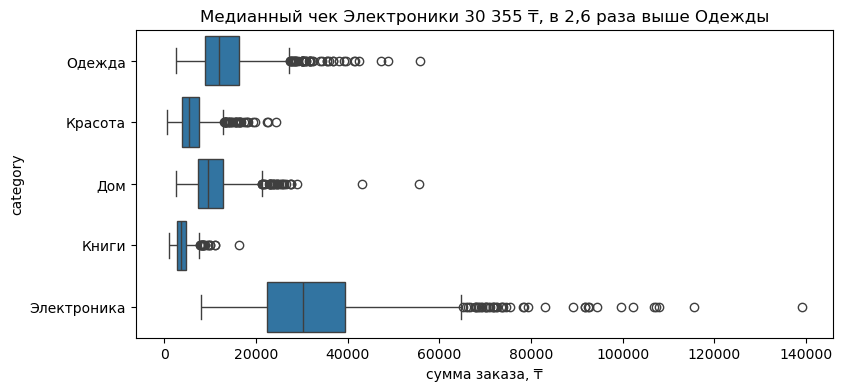

In [52]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=paid, x="amount", y="category", ax=ax)
ax.set_title("Медианный чек Электроники 30 355 ₸, в 2,6 раза выше Одежды")
ax.set_xlabel("сумма заказа, ₸")
plt.show()

In [53]:
paid.groupby("category")["amount"].describe()

,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
Дом,952.0,10633.949580,4964.563844,2570.0,7310.0,9625.0,12912.5,55650.0
Книги,564.0,3911.719858,1713.750176,970.0,2727.5,3560.0,4700.0,16330.0
Красота,857.0,6172.625438,3240.831927,720.0,3950.0,5450.0,7560.0,24390.0
Одежда,1330.0,13287.842105,6391.195747,2670.0,8922.5,11850.0,16247.5,55700.0
Электроника,1036.0,33176.090734,15505.725340,8050.0,22537.5,30355.0,39537.5,139040.0


Ящик – от Q1 до Q3 (ДЗ 5), черта внутри – медиана, усы – до 1,5 IQR, точки – выбросы по правилу IQR **своей** категории. Дорогой заказ электроники – обычное дело, дорогая книга – выброс.

### barplot: что за высота у столбика?

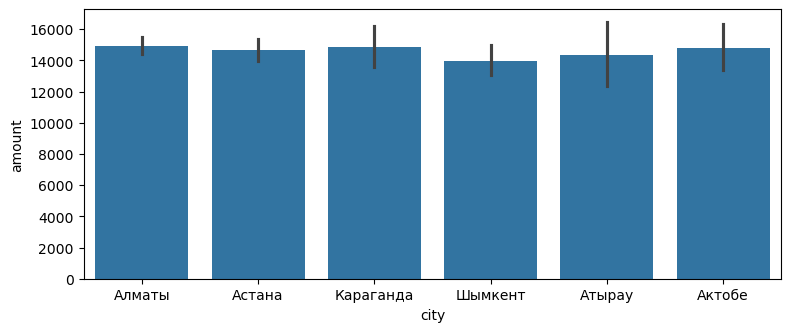

In [54]:
# ПРЕДСКАЖИТЕ: высота столбика – сумма, среднее или число заказов?
fig, ax = plt.subplots(figsize=(9, 3.5))
sns.barplot(data=paid, x="city", y="amount", ax=ax)
plt.show()

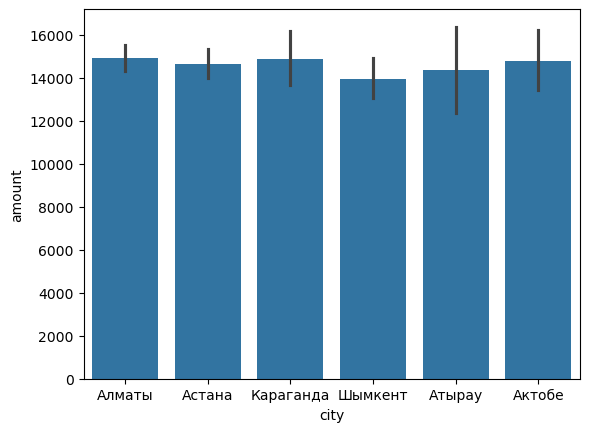

In [55]:
sns.barplot(data=paid, x="city", y="amount")
plt.show()

In [56]:
paid.groupby('city')['amount'].mean()

city
Актобе       14790.115607
Алматы       14930.373975
Астана       14647.624898
Атырау       14347.348485
Караганда    14873.305085
Шымкент      13965.357143
Name: amount, dtype: float64

In [57]:
[round(b.get_height()) for b in ax.patches]     # проверяем график числом: высоты столбиков

[14930, 14648, 14873, 13965, 14347, 14790]

In [58]:
paid.groupby("city")["amount"].mean().round()

city
Актобе       14790.0
Алматы       14930.0
Астана       14648.0
Атырау       14347.0
Караганда    14873.0
Шымкент      13965.0
Name: amount, dtype: float64

> **Частая ошибка в коде от AI:** `sns.barplot(x="city", y="amount")` под заголовком «Выручка по городам». По умолчанию barplot рисует **среднее**, а не сумму. Для выручки: `estimator="sum"`. Чёрная черта – доверительный интервал: где могло бы оказаться среднее на другой выборке. Порядок столбиков – как города встретились в данных, задаём его через `order=`.

Черта полезна для долей. Доля отмен по сроку доставки (урок 7):

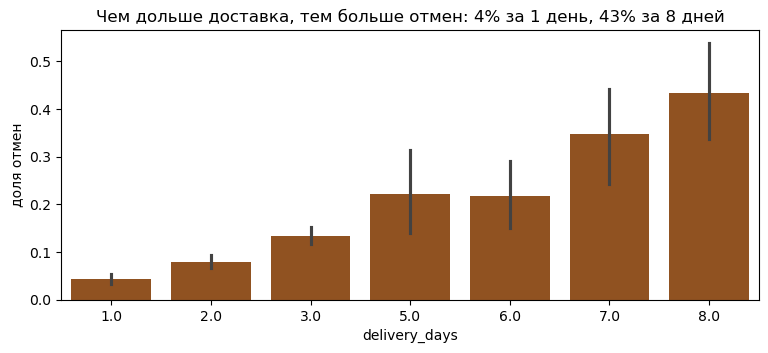

In [59]:
fig, ax = plt.subplots(figsize=(9, 3.5))
sns.barplot(data=df, x="delivery_days", y="cancel", color="#A3500E", ax=ax)
ax.set_title("Чем дольше доставка, тем больше отмен: 4% за 1 день, 43% за 8 дней")
ax.set_ylabel("доля отмен")
plt.show()

In [60]:
df.groupby("delivery_days")["cancel"].agg(["mean", "count"]).round(3)

,mean,count
delivery_days,,
1.0,0.042,1557
2.0,0.080,1570
3.0,0.134,1590
5.0,0.221,86
6.0,0.217,120
7.0,0.347,95
8.0,0.433,104


У 5–8 дней черта длиннее: там по 86–120 заказов против 1 500+ у 1–3 дней. Это картинка правила урока 7: рядом с долей – число заказов.

### Тепловая карта: таблица «X × Y» цветом
`sns.heatmap` раскрашивает `pivot_table`: чем больше число, тем темнее клетка. `annot=True` пишет числа в клетках.

In [61]:
cm = df.pivot_table(index="city", columns="month", values="cancel", aggfunc="mean")
cm

month,9,10
city,,
Актобе,0.105263,0.106599
Алматы,0.080537,0.074557
Астана,0.093233,0.083086
Атырау,0.086957,0.067568
Караганда,0.087591,0.093878
Шымкент,0.089136,0.306954


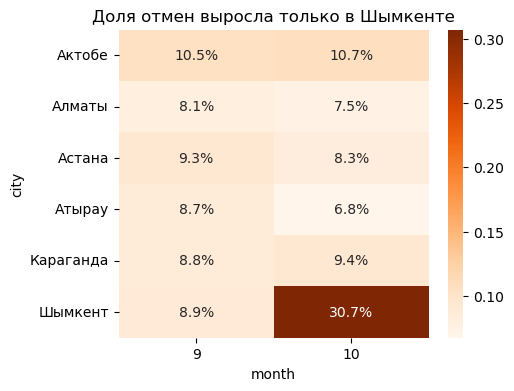

In [62]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt=".1%", cmap="Oranges", ax=ax)
ax.set_title("Доля отмен выросла только в Шымкенте")
plt.show()

### lineplot: Seaborn сам считает среднее по дням
Линия из блока 1 одной строкой: `hue` разбивает на группы, по каждой дате Seaborn сам считает среднее.

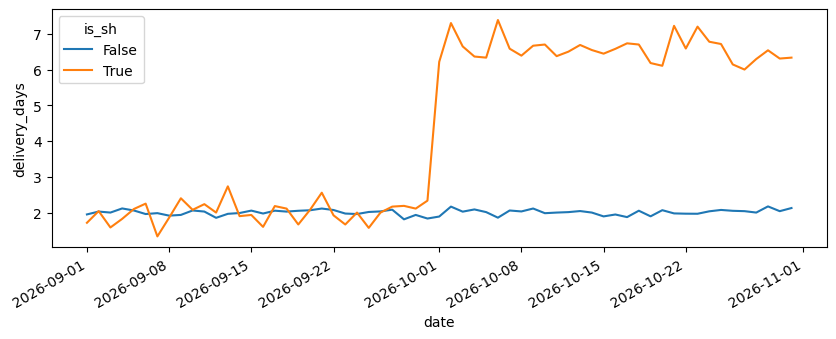

In [63]:
df["is_sh"] = df["city"] == "Шымкент"
df["date"] = df["order_date"].dt.date
fig, ax = plt.subplots(figsize=(10, 3.5))
sns.lineplot(data=df, x="date", y="delivery_days", hue="is_sh", errorbar=None, ax=ax)
fig.autofmt_xdate()
plt.show()

## Практика 2, 20 минут
1. **[База]** Ящик с усами: чек оплаченных по городам. Покупают ли в Шымкенте дешевле? Проверьте медианами.
2. **[База]** Тепловая карта «город × месяц»: средний срок доставки (`fmt=".2f"`). Какая клетка выделяется?
3. **[Стандарт]** Выручка по городам через `sns.barplot` правильно: `estimator="sum"`, `errorbar=None`, `hue="month"`, города по убыванию выручки (`order=`). Сверьте высоты столбиков с `p` (`ax.patches`).
4. **[Стандарт]** Шымкент: число заказов по сроку доставки, сентябрь и октябрь цветом (`sns.countplot(data=sh, x="delivery_days", hue="month")`). Напишите вывод для менеджера одной фразой.
5. **[Челлендж]** Доля отмен по дням (`sns.lineplot`, `hue="is_sh"`). Почему линия Шымкента шумит сильнее? Посчитайте, сколько заказов в день в Шымкенте и в остальных городах.

# 1[База] Ящик с усами: чек оплаченных по городам. Покупают ли в Шымкенте дешевле? Проверьте медианами.

In [64]:
medians = paid.groupby("city")["amount"].median().sort_values()

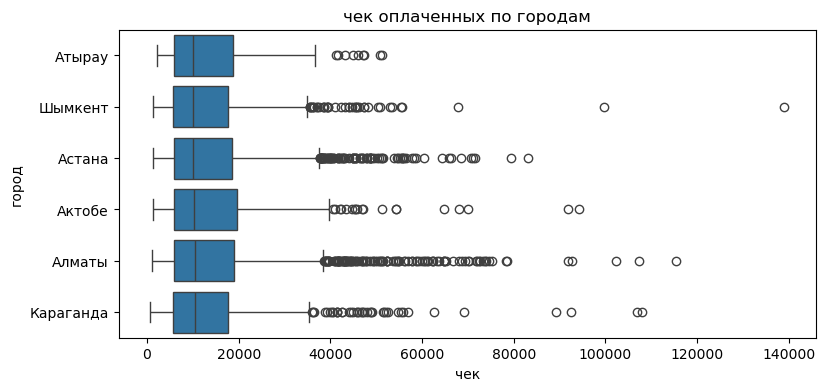

In [65]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=paid, x="amount", y="city", order=medians.index, ax=ax)
ax.set_title("чек оплаченных по городам")
ax.set_xlabel("чек")
ax.set_ylabel("город")
plt.show()

In [66]:
medians

city
Атырау        9920.0
Шымкент       9995.0
Астана       10120.0
Актобе       10210.0
Алматы       10445.0
Караганда    10455.0
Name: amount, dtype: float64

в шымкенте медианный оплаченный чек составляет 9995 это второй самый низкий показатель среди 6 городов ниже только атырау 9920

# 2[База] Тепловая карта «город × месяц»: средний срок доставки (fmt=".2f"). Какая клетка выделяется?

In [67]:
delivery = df.pivot_table(
    index="city", columns="month",
    values="delivery_days", aggfunc="mean"
)

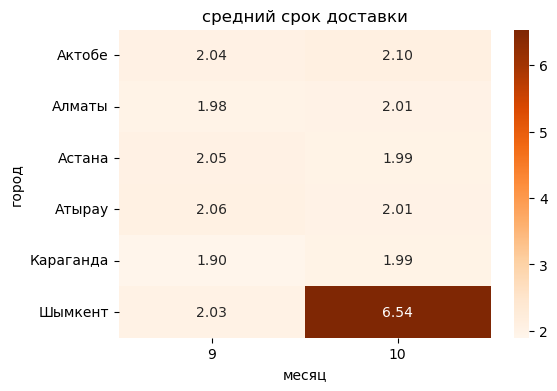

In [68]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(delivery, annot=True, fmt=".2f", cmap="Oranges", ax=ax)
ax.set_title("средний срок доставки")
ax.set_xlabel("месяц")
ax.set_ylabel("город")
plt.show()

In [69]:
delivery.round(2)

month,9,10
city,,
Актобе,2.04,2.10
Алматы,1.98,2.01
Астана,2.05,1.99
Атырау,2.06,2.01
Караганда,1.90,1.99
Шымкент,2.03,6.54


выделяется шымкент в октябре т.к средний срок доставки вырос с 2.03 до 6.54 дня то есть на 4.51 дня
в остальных городах средний срок в оба месяца оставался около двух дней

# 3[Стандарт] Выручка по городам через sns.barplot правильно: estimator="sum", errorbar=None, hue="month", города по убыванию выручки (order=). Сверьте высоты столбиков с p (ax.patches).

In [70]:
order = paid.groupby("city")["amount"].sum().sort_values(ascending=False).index

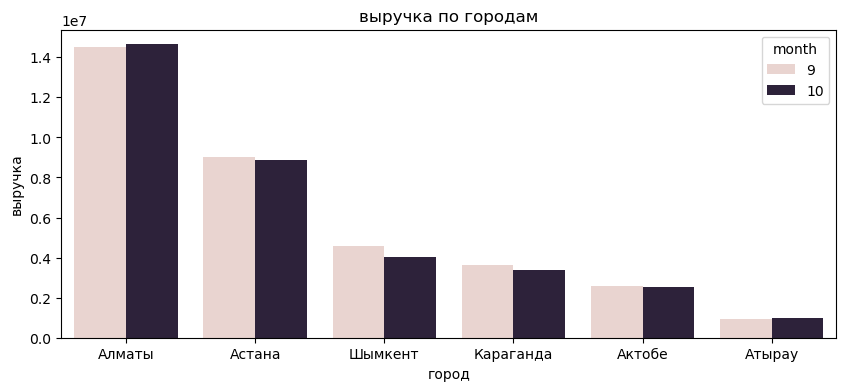

In [71]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(
    data=paid, x="city", y="amount", hue="month",
    order=order, estimator="sum", errorbar=None, ax=ax
)
ax.set_title("выручка по городам")
ax.set_xlabel("город")
ax.set_ylabel("выручка")
plt.show()

In [72]:
p.loc[order]

month,9,10
city,,
Алматы,14501070.0,14643020.0
Астана,9034220.0,8850530.0
Шымкент,4558650.0,4044010.0
Караганда,3648520.0,3371680.0
Актобе,2576960.0,2540420.0
Атырау,923990.0,969860.0


In [73]:
[b.get_height() for b in ax.patches]

[np.float64(14501070.0),
 np.float64(9034220.0),
 np.float64(4558650.0),
 np.float64(3648520.0),
 np.float64(2576960.0),
 np.float64(923990.0),
 np.float64(14643020.0),
 np.float64(8850530.0),
 np.float64(4044010.0),
 np.float64(3371680.0),
 np.float64(2540420.0),
 np.float64(969860.0),
 0,
 0]

наибольшая выручка  в алматы 14501070 в сентябре и 14643020 в октябре
в шымкенте она снизилась с 4558650 до 4044010 т.е примерно на 11.3%
это самое сильное относительное падение среди городов

# 4[Стандарт] Шымкент: число заказов по сроку доставки, сентябрь и октябрь цветом (sns.countplot(data=sh, x="delivery_days", hue="month")). Напишите вывод для менеджера одной фразой.

In [74]:
sh = df[df["city"] == "Шымкент"]

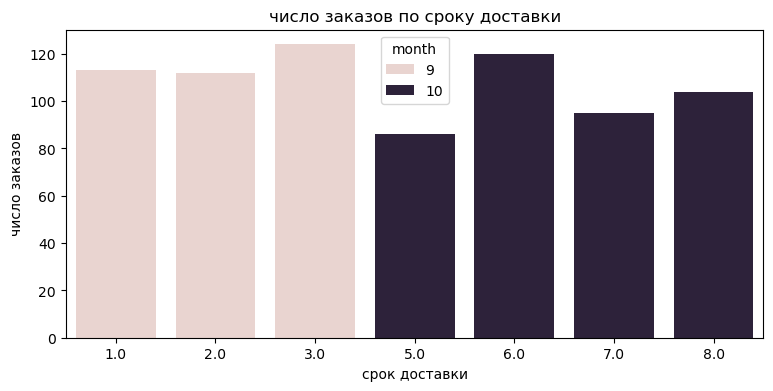

In [75]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.countplot(data=sh, x="delivery_days", hue="month", ax=ax)
ax.set_title("число заказов по сроку доставки")
ax.set_xlabel("срок доставки")
ax.set_ylabel("число заказов")
plt.show()

In [76]:
sh.groupby(["month", "delivery_days"]).size()

month  delivery_days
9      1.0              113
       2.0              112
       3.0              124
10     5.0               86
       6.0              120
       7.0               95
       8.0              104
dtype: int64

в октябре дни доставки увелечились по сравнению с сентябрем

# 5[Челлендж] Доля отмен по дням (sns.lineplot, hue="is_sh"). Почему линия Шымкента шумит сильнее? Посчитайте, сколько заказов в день в Шымкенте и в остальных городах.

In [77]:
df["is_sh"] = df["city"] == "Шымкент"
df["date"] = df["order_date"].dt.date

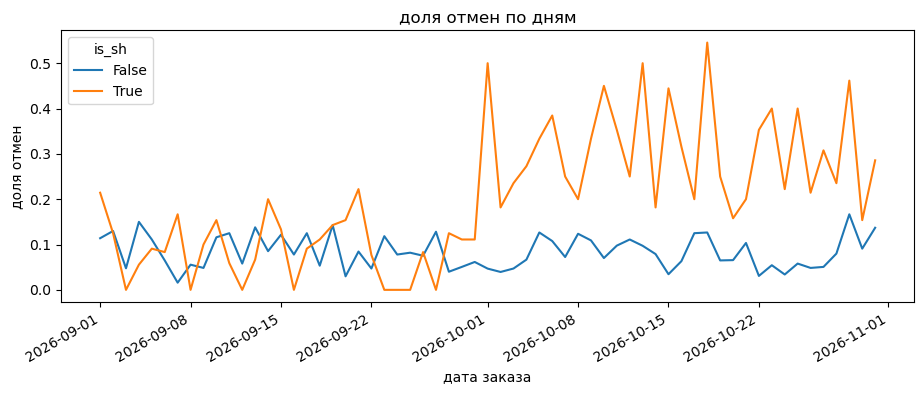

In [78]:
fig, ax = plt.subplots(figsize=(11, 4))
sns.lineplot(
    data=df, x="date", y="cancel",
    hue="is_sh", errorbar=None, ax=ax
)
ax.set_title("доля отмен по дням")
ax.set_xlabel("дата заказа")
ax.set_ylabel("доля отмен")
fig.autofmt_xdate()
plt.show()

In [79]:
df.groupby(["date", "is_sh"]).size().unstack().mean().round(1)

is_sh
False    73.8
True     12.7
dtype: float64

в шымкенте в среднем 12.7 заказа в день в остальных городах вместе  73.8 
поэтому одна отмена меняет дневную долю шымкента заметно сильнее примерно на 7.9 процентного пункта при 12.7 заказа против 1.4 пункта при 73.8 заказа 
это объясняет более резкие колебания оранжевой линии

## 3. Графики, которые врут
Один и тот же итог: выручка 35,2 → 34,4 млн ₸ (вопрос 3 разминки).

In [80]:
total

NameError: name 'total' is not defined

In [ ]:
total = paid.groupby("month")["amount"].sum() / 1e6
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].bar(["сентябрь", "октябрь"], total.values, color="gray")
axes[0].set_ylim(34, 35.5)
axes[0].set_title("Ось от 34 млн: «обвал»")
axes[1].bar(["сентябрь", "октябрь"], total.values, color="gray")
axes[1].set_title("Ось от нуля: −2,3%")
plt.show()

**Правила честного графика**
- Столбики начинаются с нуля. Обрезанная ось превращает −2,3% в «обвал втрое».
- Одна ось Y. Две оси (`ax.twinx()`) позволяют «совместить» любые две линии подбором масштаба. Разные величины – два графика рядом или индекс к общей базе (= 100).
- Подписаны единицы: ₸, млн ₸, %, дни.
- Порядок осмысленный: по значению или по времени, а не по алфавиту и не «как встретилось в данных».
- Заголовок – вывод, проверенный числом.

## Обзор Plotly: интерактивные графики (08-Plotly)
Plotly рисует график в браузере: наведите мышь – увидите значение, щёлкните по легенде – серия скроется. Удобно, чтобы **искать** в данных. Для отчёта и защиты проекта хватает Matplotlib и Seaborn.

In [ ]:
df.groupby(["date", "city"])[["delivery_days"]].mean()

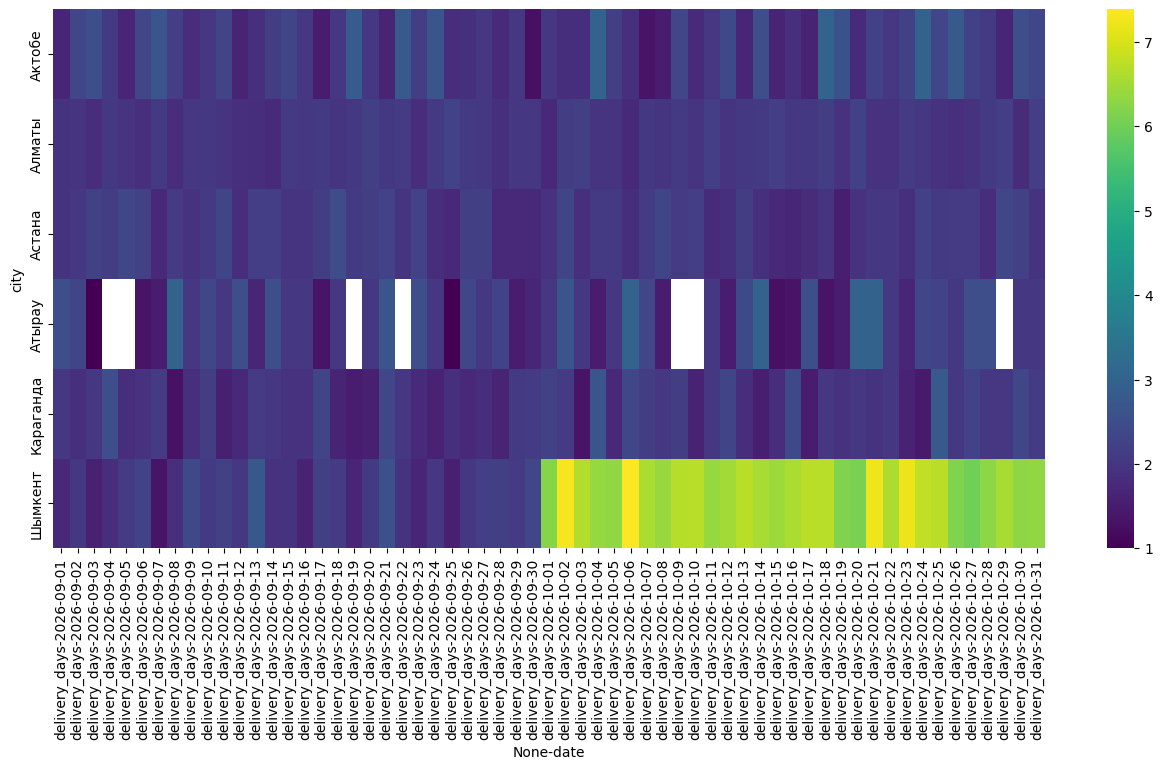

In [81]:
x = df.groupby(["city","date"])[["delivery_days"]].mean().unstack()
fig, ax = plt.subplots(figsize=(16, 7))
sns.heatmap(x, cmap='viridis',ax=ax)
plt.show()

In [82]:
df.groupby(["date", "city"])["delivery_days"].mean().reset_index()

,date,city,delivery_days
0,2026-09-01,Актобе,1.666667
1,2026-09-01,Алматы,1.942857
2,2026-09-01,Астана,1.931034
3,2026-09-01,Атырау,2.500000
4,2026-09-01,Караганда,2.000000
...,...,...,...
355,2026-10-31,Алматы,2.166667
356,2026-10-31,Астана,1.947368
357,2026-10-31,Атырау,2.000000
358,2026-10-31,Караганда,2.111111


In [83]:
import plotly.express as px

day = df.groupby(["date", "city"])["delivery_days"].mean().reset_index()
day.head()

,date,city,delivery_days
0,2026-09-01,Актобе,1.666667
1,2026-09-01,Алматы,1.942857
2,2026-09-01,Астана,1.931034
3,2026-09-01,Атырау,2.500000
4,2026-09-01,Караганда,2.000000


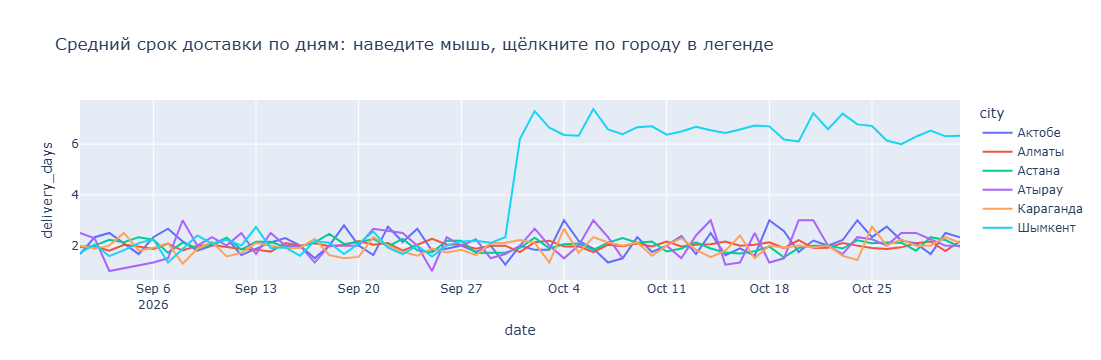

In [84]:
fig = px.line(day, x="date", y="delivery_days", color="city",
              title="Средний срок доставки по дням: наведите мышь, щёлкните по городу в легенде")
fig

`fig.write_html("delivery.html")` сохраняет интерактивный график в файл, который открывается в любом браузере. GitHub не показывает графики Plotly в ноутбуке, поэтому в ДЗ вывод пишем словами.

## Практика 3, 15 минут: дашборд для менеджера
Менеджер спрашивал: «Почему выручка в октябре упала на 22,7%?» Ответ – одна картинка из четырёх графиков: `fig, axes = plt.subplots(2, 2, figsize=(14, 9))`, графики в `axes[0, 0]`, `axes[0, 1]`, `axes[1, 0]`, `axes[1, 1]`.
1. **[База]** `axes[0, 0]`: выручка оплаченных по месяцам, ось от нуля.
2. **[База]** `axes[0, 1]`: изменение выручки по городам, Шымкент цветом.
3. **[Стандарт]** `axes[1, 0]`: средний срок доставки по дням, Шымкент и остальные города.
4. **[Стандарт]** `axes[1, 1]`: доля отмен по сроку доставки.
5. **[Челлендж]** Общий заголовок-вывод (`fig.suptitle`), `fig.tight_layout()`, сохраните в `dashboard.png`. Под картинкой – вывод для менеджера в три предложения: что случилось, сколько стоило, что делать.

# 1–4
[База] axes[0, 0]: выручка оплаченных по месяцам, ось от нуля.
[База] axes[0, 1]: изменение выручки по городам, Шымкент цветом.
[Стандарт] axes[1, 0]: средний срок доставки по дням, Шымкент и остальные города.
[Стандарт] axes[1, 1]: доля отмен по сроку доставки.

Text(0, 0.5, 'доля отмен, %')

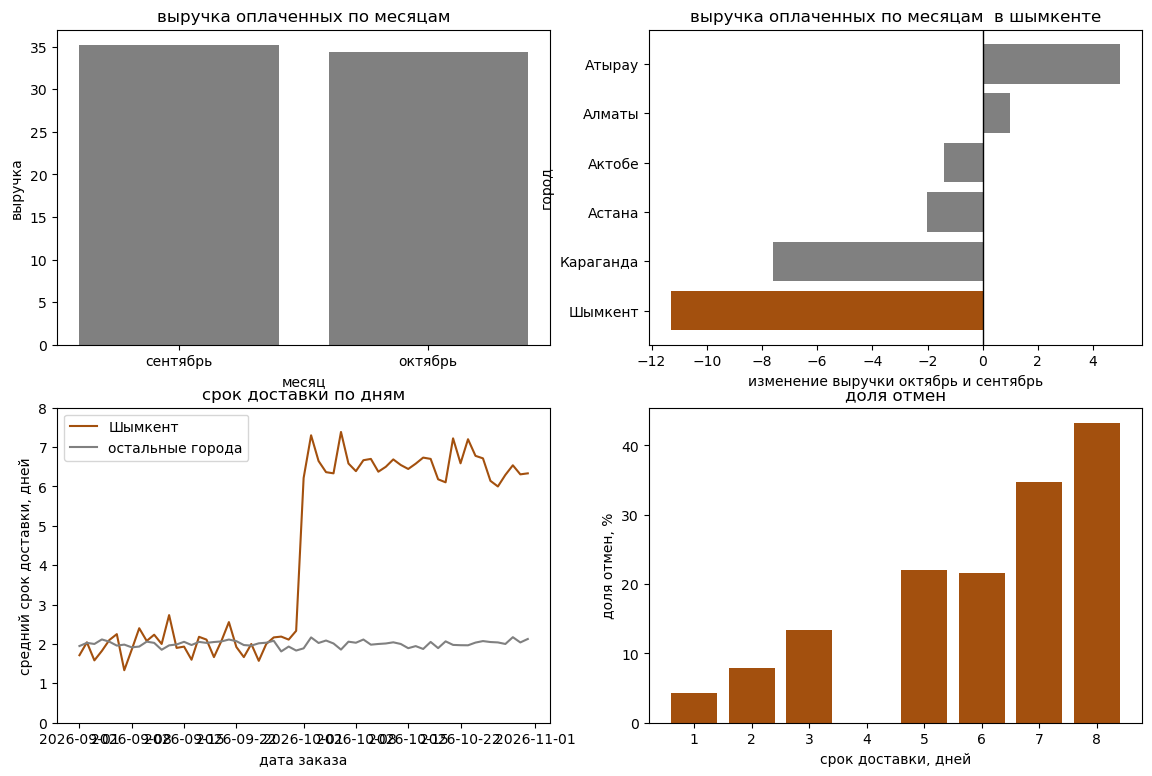

In [86]:
paid = df[df["status"] == "оплачен"]
df["cancel"] = df["status"] == "отменён"
monthly = paid.groupby("month")["amount"].sum() / 1e6
p = paid.pivot_table(
    index="city", columns="month", values="amount", aggfunc="sum"
)
city_change = ((p[10] / p[9] - 1) * 100).sort_values()
sh = df[df["city"] == "Шымкент"]
other = df[df["city"] != "Шымкент"]
sh_day = sh.groupby(sh["order_date"].dt.date)["delivery_days"].mean()
other_day = other.groupby(other["order_date"].dt.date)["delivery_days"].mean()
cancel_by_days = df.groupby("delivery_days")["cancel"].mean() * 100
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes[0, 0].bar(["сентябрь", "октябрь"], monthly.values, color="gray")
axes[0, 0].set_ylim(bottom=0)
axes[0, 0].set_title("выручка оплаченных по месяцам")
axes[0, 0].set_xlabel("месяц")
axes[0, 0].set_ylabel("выручка")
colors = ["#A3500E" if city == "Шымкент" else "gray"
          for city in city_change.index]
axes[0, 1].barh(city_change.index, city_change.values, color=colors)
axes[0, 1].axvline(0, color="black", linewidth=1)
axes[0, 1].set_title("выручка оплаченных по месяцам  в шымкенте")
axes[0, 1].set_xlabel("изменение выручки октябрь и сентябрь")
axes[0, 1].set_ylabel("город")
axes[1, 0].plot(sh_day.index, sh_day.values,
                color="#A3500E", label="Шымкент")
axes[1, 0].plot(other_day.index, other_day.values,
                color="gray", label="остальные города")
axes[1, 0].set_title("срок доставки по дням")
axes[1, 0].set_xlabel("дата заказа")
axes[1, 0].set_ylabel("средний срок доставки, дней")
axes[1, 0].set_ylim(0, 8)
axes[1, 0].legend()
axes[1, 1].bar(cancel_by_days.index, cancel_by_days.values,
               color="#A3500E")
axes[1, 1].set_ylim(bottom=0)
axes[1, 1].set_title("доля отмен")
axes[1, 1].set_xlabel("срок доставки, дней")
axes[1, 1].set_ylabel("доля отмен, %")

# 5
[Челлендж] Общий заголовок-вывод (fig.suptitle), fig.tight_layout(), сохраните в dashboard.png. Под картинкой – вывод для менеджера в три предложения: что случилось, сколько стоило, что делать.

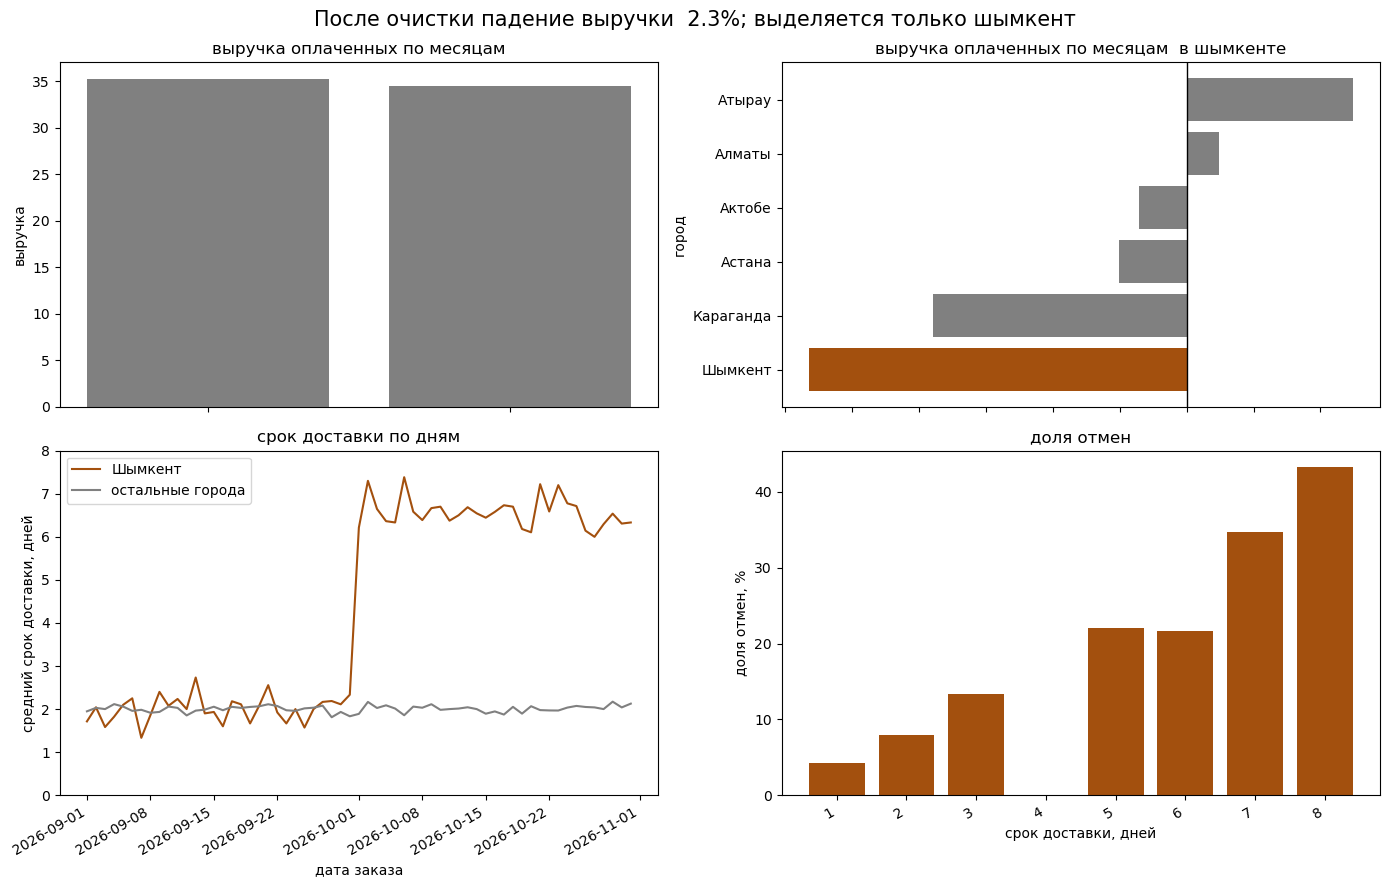

In [88]:
fig.suptitle(
    "После очистки падение выручки  2.3%; выделяется только шымкент",
    fontsize=15
)
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig("dashboard.png", dpi=150, bbox_inches="tight")
fig

после очистки данных выручка в октябре снизилась на 2.3%, а не на 2.7% с 35243410 до 34419520 
из общего снижения на 823890 на шымкент приходится 514640 или 62.5%
с начала октября средний срок доставки там вырос с 2.03 до 6.54 дня и при длительной доставке доля отмен выше
необходимо проверить что изменилось в доставке шымкента с 1 октября графики показывают совпадение этих изменений но не доказывают причину сбоя

## Итоги

| Вопрос | График | Проверка |
|---|---|---|
| Как менялось во времени? | линия: `ax.plot(x, y)`, x – дата | отсортировано по времени |
| Какая группа выделяется? | столбики: `ax.barh(...)`, отсортировано | ось от нуля, цвет на главном |
| Как распределены суммы? | `ax.hist`, `sns.boxplot` | один столбик и пустота → выброс |
| Таблица «X × Y» | `sns.heatmap(pivot_table, annot=True)` | рядом число заказов |
| Seaborn barplot | `sns.barplot(..., estimator="sum")` | по умолчанию это среднее |

Падение −2,3% на одной картинке: с 1 октября доставка в Шымкенте идёт 6–7 дней, при таком сроке отменяют 22–43% заказов, и выручка Шымкента падает на 11,3%.

**ДЗ 8:** ноутбук HW08_visualization, сдача в папку `hw08` репозитория `dsa-homework`. На уроке 9 – воркшоп EDA-проекта: графики из ДЗ 8 пригодятся в проекте.